# Laborator: Generative Adversarial Network (GAN) pentru MNIST

**Curs:** Modele Generative  
**Scop:** implementarea, antrenarea și evaluarea unui GAN dens care generează cifre similare imaginilor MNIST.

## Obiective
1. Încărcarea și explorarea setului MNIST.
2. Preprocesarea imaginilor în intervalul `[-1, 1]`.
3. Construirea generatorului și discriminatorului.
4. Implementarea buclei adversariale de antrenare.
5. Vizualizarea progresului și analiza pierderilor.
6. Generarea și salvarea unor exemple noi.

## 1. Principiul GAN
Generatorul transformă zgomotul latent $z$ într-o imagine artificială $G(z)$. Discriminatorul estimează dacă o imagine este reală sau generată. Cele două rețele sunt optimizate alternativ.

Funcția obiectiv originală este:

$$\min_G \max_D \; \mathbb{E}_{x \sim p_{data}}[\log D(x)] + \mathbb{E}_{z \sim p_z}[\log(1-D(G(z)))]$$

În implementare folosim Binary Cross-Entropy pe logits și optimizatorul Adam.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)
print('GPU-uri disponibile:', tf.config.list_physical_devices('GPU'))

I0000 00:00:1790001969.598152 2804807 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790001969.637661 2804807 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790001970.731577 2804807 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
Keras: 3.15.1
GPU-uri disponibile: []


E0000 00:00:1790001971.492307 2804807 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Configurarea experimentului
Pentru o probă rapidă se pot folosi `EPOCHS = 5`. Pentru rezultate mai clare sunt recomandate 30–50 de epoci.

In [33]:
BATCH_SIZE = 256
LATENT_DIM = 200
EPOCHS = 60
LEARNING_RATE = 2e-4
BETA_1 = 0.5
BUFFER_SIZE = 60_000
NUM_EXAMPLES_TO_GENERATE = 16

OUTPUT_DIR = Path('gan_mnist_outputs')
IMAGE_DIR = OUTPUT_DIR / 'images'
MODEL_DIR = OUTPUT_DIR / 'models'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

fixed_seed = tf.random.normal([NUM_EXAMPLES_TO_GENERATE, LATENT_DIM], seed=SEED)

## 3. Încărcarea și explorarea MNIST
MNIST conține imagini grayscale de `28 × 28` pixeli. Etichetele nu sunt necesare pentru GAN-ul necondiționat. La prima rulare, TensorFlow descarcă automat setul de date.

Antrenare: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)
Interval pixeli: 0 255


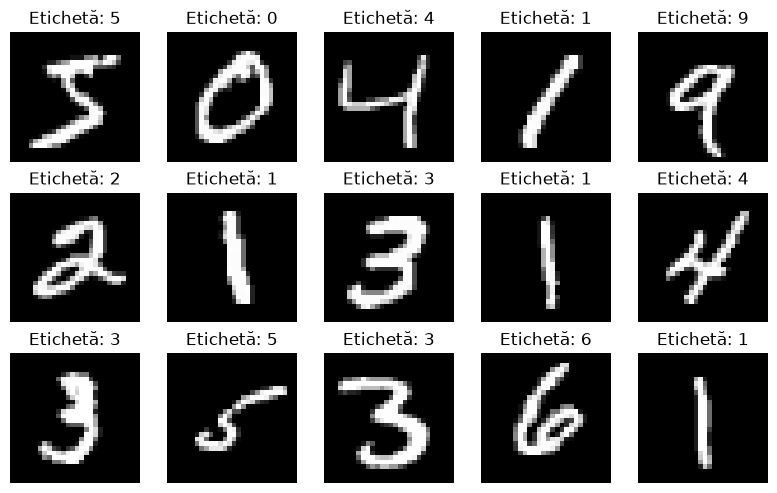

In [34]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print('Antrenare:', x_train.shape, y_train.shape)
print('Test:', x_test.shape, y_test.shape)
print('Interval pixeli:', x_train.min(), x_train.max())

fig, axes = plt.subplots(3, 5, figsize=(8, 5))
for ax, image, label in zip(axes.ravel(), x_train[:15], y_train[:15]):
    ax.imshow(image, cmap='gray')
    ax.set_title(f'Etichetă: {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Preprocesarea datelor
Generatorul folosește `tanh`, deci imaginile reale sunt convertite la `float32`, li se adaugă canalul grayscale și sunt normalizate din `[0, 255]` în `[-1, 1]`.

In [35]:
x_train = x_train.astype('float32')
x_train = np.expand_dims(x_train, axis=-1)
x_train = (x_train - 127.5) / 127.5

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print('Forma datelor:', x_train.shape)
print('Interval normalizat:', x_train.min(), x_train.max())
print('Număr loturi:', tf.data.experimental.cardinality(train_dataset).numpy())

Forma datelor: (60000, 28, 28, 1)
Interval normalizat: -1.0 1.0
Număr loturi: 234


## 5. Generatorul
Vectorul latent este proiectat într-o imagine de `28 × 28 × 1`. `BatchNormalization` stabilizează învățarea, iar activarea finală `tanh` corespunde normalizării în `[-1, 1]`.

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 256)            │        51,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 512)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1024)           │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,517,328 (5.79 MB)

 Trainable params: 1,513,744 (5.77 MB)

 Non-trainable params: 3,584 (14.00 KB)

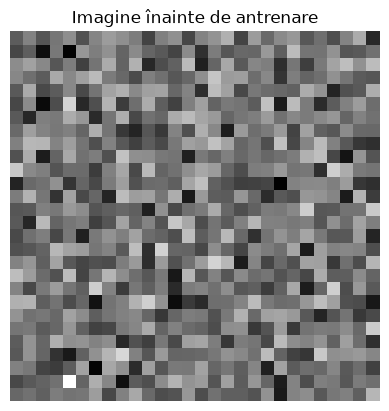

In [36]:
def build_generator(latent_dim=LATENT_DIM):
    model = keras.Sequential([
        layers.Input(shape=(latent_dim,)),
        layers.Dense(256, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(512, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(1024, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dense(28 * 28, activation='tanh'),
        layers.Reshape((28, 28, 1)),
    ], name='generator')
    return model

generator = build_generator()
generator.summary()

sample_image = generator(tf.random.normal([1, LATENT_DIM]), training=False)
assert sample_image.shape == (1, 28, 28, 1)
plt.imshow((sample_image[0, :, :, 0] + 1) / 2, cmap='gray')
plt.axis('off')
plt.title('Imagine înainte de antrenare')
plt.show()

## 6. Discriminatorul
Discriminatorul întoarce un singur logit. Nu folosim `sigmoid` în ultimul strat deoarece funcția de pierdere este configurată cu `from_logits=True`.

In [37]:
def build_discriminator():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(512),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),
        layers.Dense(256),
        layers.LeakyReLU(negative_slope=0.2),
        layers.Dropout(0.3),
        layers.Dense(1),
    ], name='discriminator')
    return model

discriminator = build_discriminator()
discriminator.summary()
print('Logit pentru imaginea neantrenată:', discriminator(sample_image, training=False).numpy().ravel()[0])

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

Logit pentru imaginea neantrenată: 0.13122007


## 7. Pierderile și optimizatorii
Discriminatorul compară imaginile reale cu 1 și imaginile false cu 0. Generatorul încearcă să obțină pentru imaginile sale predicția 1. Optimizatorii sunt separați deoarece fiecare rețea are propriii parametri.

In [38]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_logits, fake_logits):
    real_loss = cross_entropy(tf.ones_like(real_logits), real_logits)
    fake_loss = cross_entropy(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return cross_entropy(tf.ones_like(fake_logits), fake_logits)

generator_optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)
discriminator_optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)

## 8. Un pas de antrenare
Cu două benzi de gradient calculăm simultan pierderile, dar aplicăm separat gradienții. `@tf.function` compilează operațiile pentru execuție eficientă.

In [39]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)

        gen_loss = generator_loss(fake_logits)
        disc_loss = discriminator_loss(real_logits, fake_logits)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    real_accuracy = tf.reduce_mean(tf.cast(real_logits > 0, tf.float32))
    fake_accuracy = tf.reduce_mean(tf.cast(fake_logits < 0, tf.float32))
    return gen_loss, disc_loss, real_accuracy, fake_accuracy

In [40]:
def generate_and_save_images(model, epoch, test_input, show=True):
    predictions = model(test_input, training=False)
    predictions = (predictions + 1.0) / 2.0
    predictions = tf.clip_by_value(predictions, 0.0, 1.0)

    fig = plt.figure(figsize=(6, 6))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap='gray', vmin=0, vmax=1)
        plt.axis('off')
    plt.suptitle(f'Epoca {epoch}')
    plt.tight_layout()
    filename = IMAGE_DIR / f'epoch_{epoch:03d}.png'
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(fig)
    return filename

## 9. Antrenarea completă
Aceiași vectori `fixed_seed` sunt folosiți după fiecare epocă, astfel încât progresul să poată fi comparat corect. Rulați celula următoare pentru antrenare.

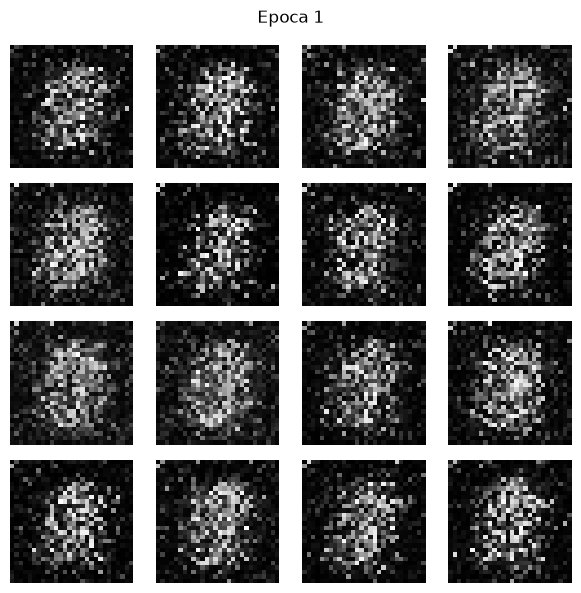

Epoca 001/60 | G: 1.0261 | D: 1.0304 | acc_real: 0.807 | acc_fake: 0.660 | 8.2s
Epoca 002/60 | G: 0.9136 | D: 1.1552 | acc_real: 0.736 | acc_fake: 0.660 | 6.5s
Epoca 003/60 | G: 0.8421 | D: 1.2255 | acc_real: 0.702 | acc_fake: 0.615 | 6.5s
Epoca 004/60 | G: 0.8593 | D: 1.2205 | acc_real: 0.699 | acc_fake: 0.629 | 6.7s


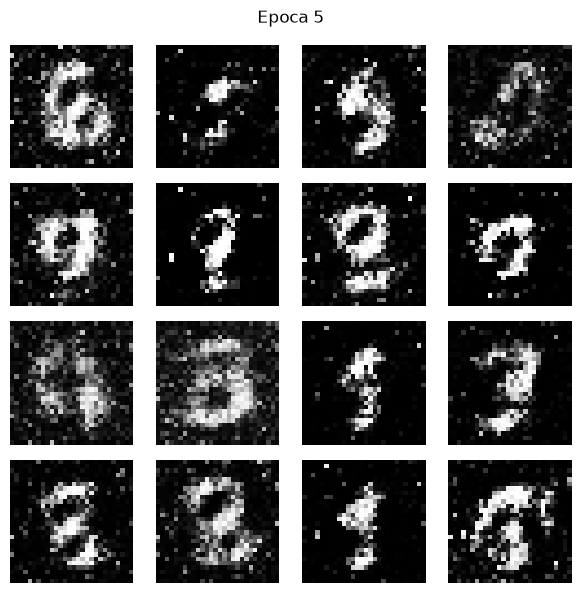

Epoca 005/60 | G: 0.8783 | D: 1.2118 | acc_real: 0.698 | acc_fake: 0.644 | 6.5s
Epoca 006/60 | G: 0.8557 | D: 1.2283 | acc_real: 0.685 | acc_fake: 0.637 | 6.5s
Epoca 007/60 | G: 0.8457 | D: 1.2380 | acc_real: 0.673 | acc_fake: 0.636 | 6.5s
Epoca 008/60 | G: 0.9027 | D: 1.1983 | acc_real: 0.685 | acc_fake: 0.672 | 6.5s
Epoca 009/60 | G: 0.8934 | D: 1.1970 | acc_real: 0.677 | acc_fake: 0.677 | 6.5s


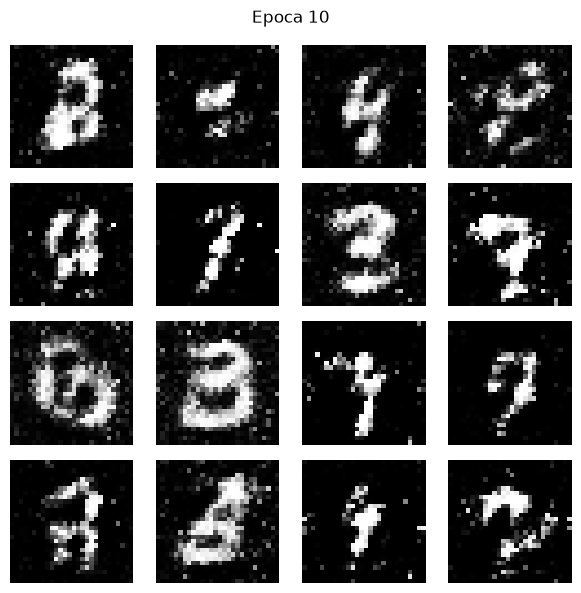

Epoca 010/60 | G: 0.9266 | D: 1.1768 | acc_real: 0.687 | acc_fake: 0.691 | 6.5s
Epoca 011/60 | G: 0.9490 | D: 1.1642 | acc_real: 0.678 | acc_fake: 0.707 | 6.5s
Epoca 012/60 | G: 0.9402 | D: 1.1699 | acc_real: 0.677 | acc_fake: 0.700 | 6.7s
Epoca 013/60 | G: 0.9570 | D: 1.1633 | acc_real: 0.676 | acc_fake: 0.709 | 6.5s
Epoca 014/60 | G: 0.9845 | D: 1.1479 | acc_real: 0.677 | acc_fake: 0.719 | 6.5s


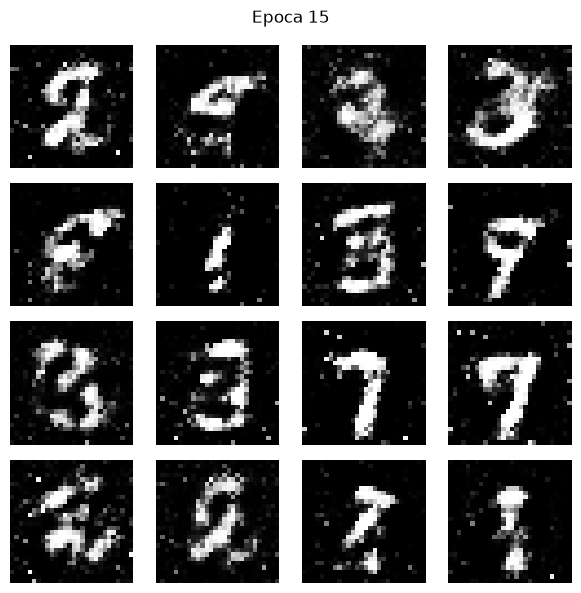

Epoca 015/60 | G: 0.9829 | D: 1.1482 | acc_real: 0.674 | acc_fake: 0.723 | 6.5s
Epoca 016/60 | G: 0.9624 | D: 1.1593 | acc_real: 0.669 | acc_fake: 0.719 | 6.5s
Epoca 017/60 | G: 0.9555 | D: 1.1754 | acc_real: 0.660 | acc_fake: 0.708 | 6.5s
Epoca 018/60 | G: 0.9468 | D: 1.1808 | acc_real: 0.664 | acc_fake: 0.706 | 6.5s
Epoca 019/60 | G: 0.9348 | D: 1.1955 | acc_real: 0.657 | acc_fake: 0.701 | 6.7s


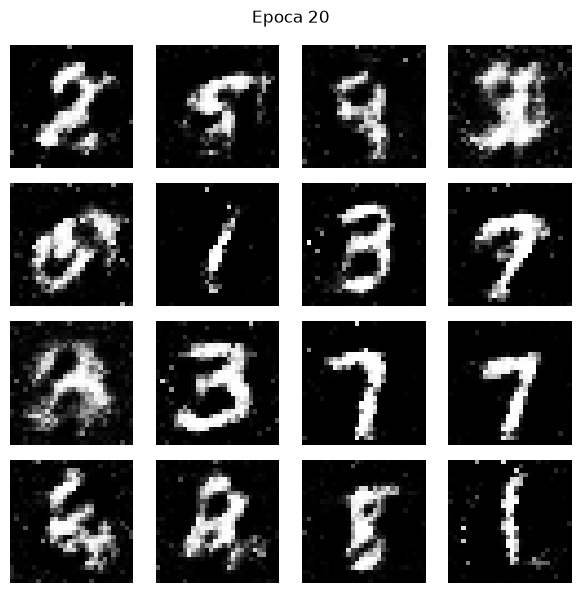

Epoca 020/60 | G: 0.9265 | D: 1.2060 | acc_real: 0.647 | acc_fake: 0.698 | 6.5s
Epoca 021/60 | G: 0.9319 | D: 1.2042 | acc_real: 0.646 | acc_fake: 0.699 | 6.5s
Epoca 022/60 | G: 0.9144 | D: 1.2150 | acc_real: 0.642 | acc_fake: 0.692 | 6.5s
Epoca 023/60 | G: 0.9114 | D: 1.2234 | acc_real: 0.636 | acc_fake: 0.690 | 6.5s
Epoca 024/60 | G: 0.9051 | D: 1.2262 | acc_real: 0.637 | acc_fake: 0.687 | 6.5s


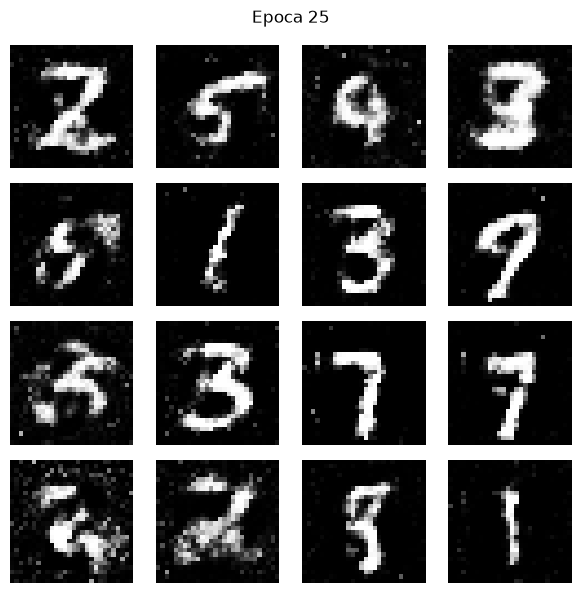

Epoca 025/60 | G: 0.9067 | D: 1.2322 | acc_real: 0.633 | acc_fake: 0.685 | 6.5s
Epoca 026/60 | G: 0.9012 | D: 1.2347 | acc_real: 0.632 | acc_fake: 0.683 | 6.5s
Epoca 027/60 | G: 0.8870 | D: 1.2476 | acc_real: 0.623 | acc_fake: 0.680 | 6.7s
Epoca 028/60 | G: 0.8830 | D: 1.2518 | acc_real: 0.623 | acc_fake: 0.674 | 6.5s
Epoca 029/60 | G: 0.8883 | D: 1.2436 | acc_real: 0.628 | acc_fake: 0.677 | 6.6s


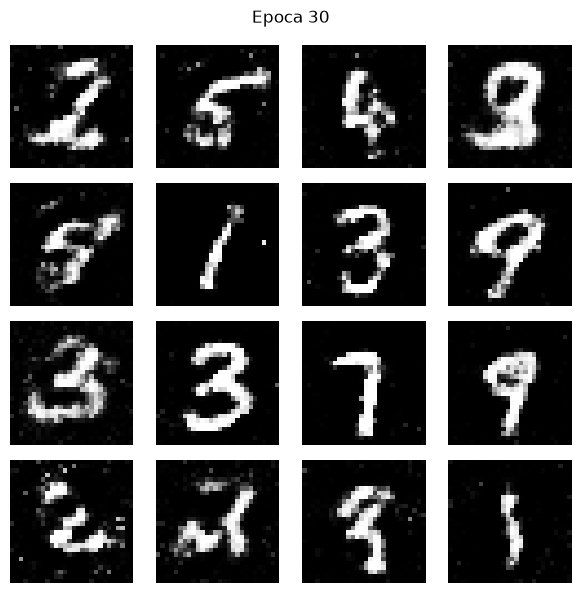

Epoca 030/60 | G: 0.8854 | D: 1.2581 | acc_real: 0.619 | acc_fake: 0.672 | 6.5s
Epoca 031/60 | G: 0.8756 | D: 1.2576 | acc_real: 0.618 | acc_fake: 0.673 | 6.4s
Epoca 032/60 | G: 0.8722 | D: 1.2636 | acc_real: 0.616 | acc_fake: 0.668 | 6.4s
Epoca 033/60 | G: 0.8687 | D: 1.2670 | acc_real: 0.612 | acc_fake: 0.668 | 6.6s
Epoca 034/60 | G: 0.8649 | D: 1.2703 | acc_real: 0.608 | acc_fake: 0.666 | 6.4s


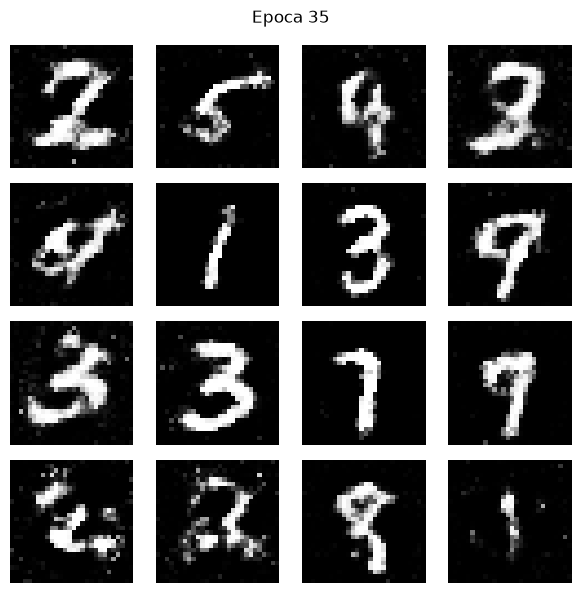

Epoca 035/60 | G: 0.8573 | D: 1.2766 | acc_real: 0.608 | acc_fake: 0.661 | 6.5s
Epoca 036/60 | G: 0.8568 | D: 1.2754 | acc_real: 0.612 | acc_fake: 0.660 | 6.5s
Epoca 037/60 | G: 0.8571 | D: 1.2802 | acc_real: 0.603 | acc_fake: 0.658 | 6.4s
Epoca 038/60 | G: 0.8555 | D: 1.2772 | acc_real: 0.605 | acc_fake: 0.660 | 6.5s
Epoca 039/60 | G: 0.8470 | D: 1.2857 | acc_real: 0.598 | acc_fake: 0.656 | 6.5s


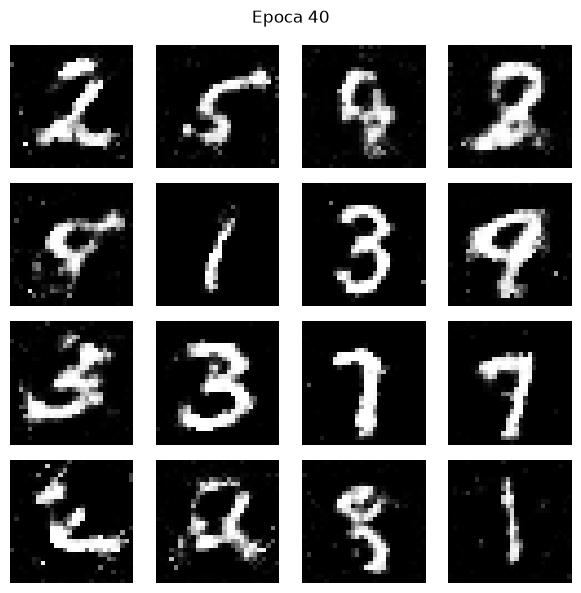

Epoca 040/60 | G: 0.8445 | D: 1.2853 | acc_real: 0.602 | acc_fake: 0.654 | 6.5s
Epoca 041/60 | G: 0.8464 | D: 1.2860 | acc_real: 0.602 | acc_fake: 0.655 | 6.7s
Epoca 042/60 | G: 0.8457 | D: 1.2859 | acc_real: 0.603 | acc_fake: 0.652 | 6.5s
Epoca 043/60 | G: 0.8478 | D: 1.2865 | acc_real: 0.600 | acc_fake: 0.654 | 6.5s
Epoca 044/60 | G: 0.8442 | D: 1.2852 | acc_real: 0.602 | acc_fake: 0.655 | 6.4s


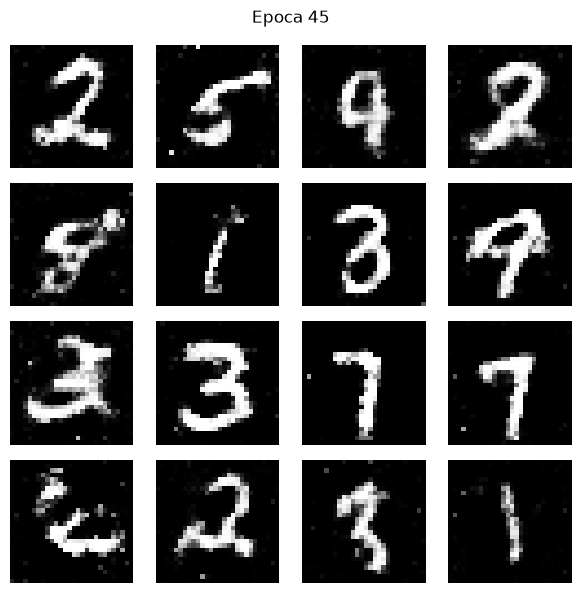

Epoca 045/60 | G: 0.8397 | D: 1.2912 | acc_real: 0.596 | acc_fake: 0.651 | 6.5s
Epoca 046/60 | G: 0.8385 | D: 1.2933 | acc_real: 0.594 | acc_fake: 0.650 | 6.4s
Epoca 047/60 | G: 0.8426 | D: 1.2891 | acc_real: 0.597 | acc_fake: 0.652 | 6.4s
Epoca 048/60 | G: 0.8362 | D: 1.2946 | acc_real: 0.594 | acc_fake: 0.646 | 6.6s
Epoca 049/60 | G: 0.8356 | D: 1.2945 | acc_real: 0.597 | acc_fake: 0.651 | 6.4s


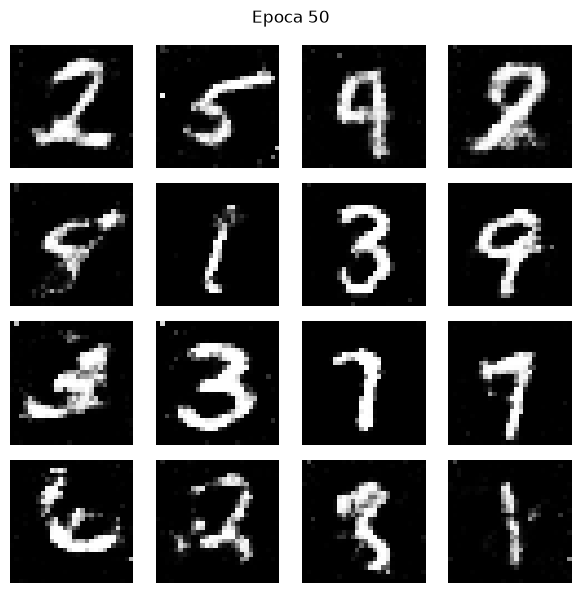

Epoca 050/60 | G: 0.8336 | D: 1.2944 | acc_real: 0.596 | acc_fake: 0.649 | 6.5s
Epoca 051/60 | G: 0.8342 | D: 1.2960 | acc_real: 0.593 | acc_fake: 0.648 | 6.4s
Epoca 052/60 | G: 0.8298 | D: 1.2982 | acc_real: 0.592 | acc_fake: 0.646 | 6.4s
Epoca 053/60 | G: 0.8303 | D: 1.2984 | acc_real: 0.593 | acc_fake: 0.645 | 6.4s
Epoca 054/60 | G: 0.8278 | D: 1.2990 | acc_real: 0.589 | acc_fake: 0.646 | 6.4s


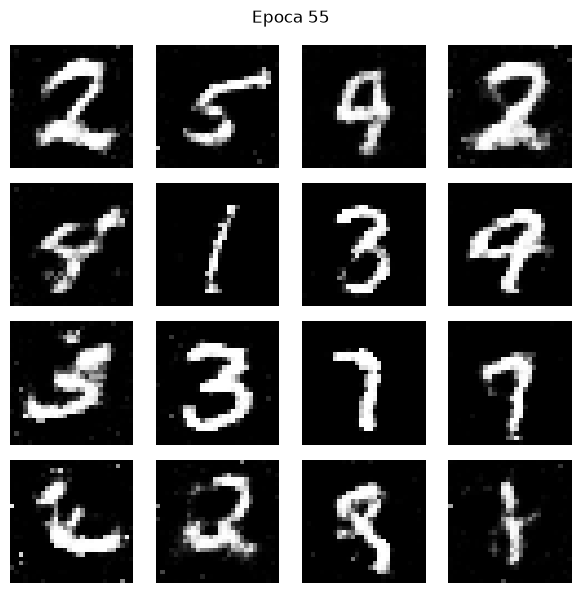

Epoca 055/60 | G: 0.8298 | D: 1.3004 | acc_real: 0.590 | acc_fake: 0.646 | 6.6s
Epoca 056/60 | G: 0.8283 | D: 1.3001 | acc_real: 0.591 | acc_fake: 0.645 | 6.4s
Epoca 057/60 | G: 0.8315 | D: 1.2962 | acc_real: 0.593 | acc_fake: 0.647 | 6.4s
Epoca 058/60 | G: 0.8232 | D: 1.3032 | acc_real: 0.593 | acc_fake: 0.642 | 6.4s
Epoca 059/60 | G: 0.8257 | D: 1.3000 | acc_real: 0.590 | acc_fake: 0.645 | 6.4s


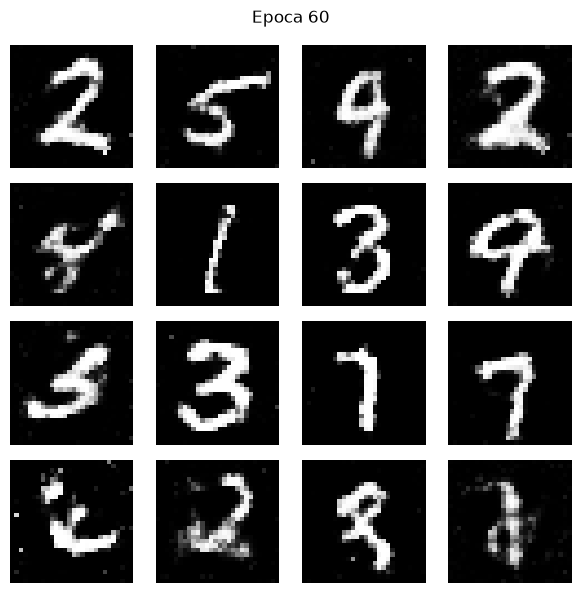

Epoca 060/60 | G: 0.8252 | D: 1.3023 | acc_real: 0.591 | acc_fake: 0.642 | 6.4s


In [41]:
import time

history = {'generator_loss': [], 'discriminator_loss': [], 'real_accuracy': [], 'fake_accuracy': []}

def train(dataset, epochs):
    for epoch in range(1, epochs + 1):
        start = time.time()
        metrics = {name: keras.metrics.Mean() for name in history}

        for image_batch in dataset:
            gen_loss, disc_loss, real_acc, fake_acc = train_step(image_batch)
            metrics['generator_loss'].update_state(gen_loss)
            metrics['discriminator_loss'].update_state(disc_loss)
            metrics['real_accuracy'].update_state(real_acc)
            metrics['fake_accuracy'].update_state(fake_acc)

        epoch_values = {name: float(metric.result().numpy()) for name, metric in metrics.items()}
        for name, value in epoch_values.items():
            history[name].append(value)

        generate_and_save_images(generator, epoch, fixed_seed, show=(epoch == 1 or epoch % 5 == 0 or epoch == epochs))
        elapsed = time.time() - start
        print(f"Epoca {epoch:03d}/{epochs} | G: {epoch_values['generator_loss']:.4f} | "
              f"D: {epoch_values['discriminator_loss']:.4f} | "
              f"acc_real: {epoch_values['real_accuracy']:.3f} | "
              f"acc_fake: {epoch_values['fake_accuracy']:.3f} | {elapsed:.1f}s")

train(train_dataset, EPOCHS)

## 10. Analiza curbelor
La GAN nu se urmărește o scădere monotonă a ambelor pierderi. Oscilațiile sunt normale. Semnalul principal rămâne evoluția vizuală și diversitatea imaginilor. O acuratețe constantă de 100% a discriminatorului poate indica faptul că acesta domină generatorul.

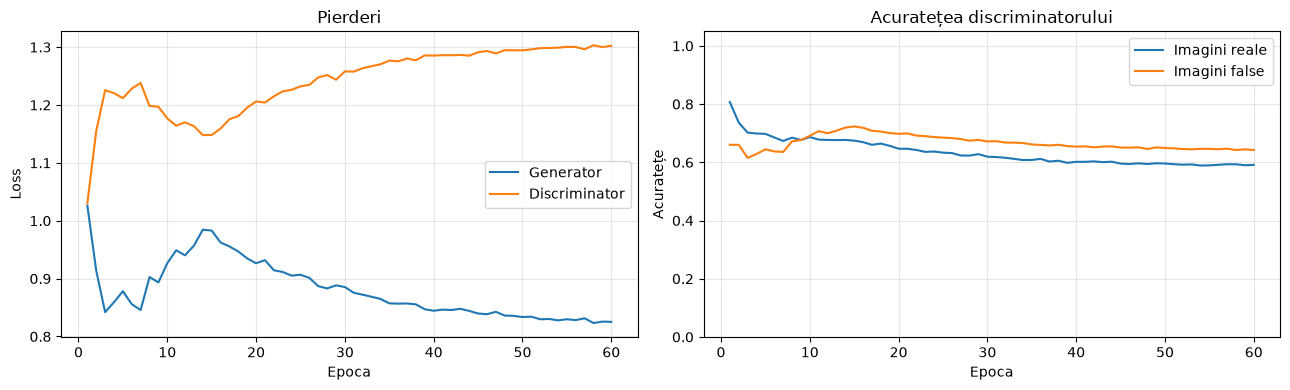

In [42]:
epochs_axis = np.arange(1, len(history['generator_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_axis, history['generator_loss'], label='Generator')
axes[0].plot(epochs_axis, history['discriminator_loss'], label='Discriminator')
axes[0].set(title='Pierderi', xlabel='Epoca', ylabel='Loss')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_axis, history['real_accuracy'], label='Imagini reale')
axes[1].plot(epochs_axis, history['fake_accuracy'], label='Imagini false')
axes[1].set(title='Acuratețea discriminatorului', xlabel='Epoca', ylabel='Acuratețe', ylim=(0, 1.05))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Generarea unor imagini noi
Folosim vectori latenți noi, diferiți de cei utilizați pentru monitorizarea antrenării.

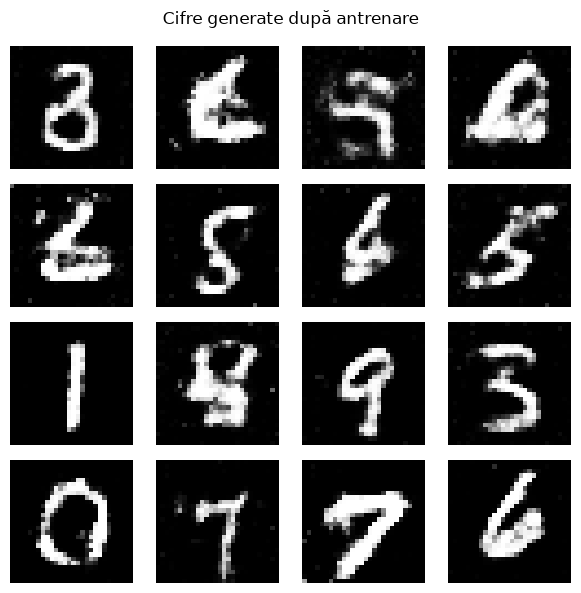

In [30]:
new_noise = tf.random.normal([16, LATENT_DIM])
generated_images = generator(new_noise, training=False)
generated_images = tf.clip_by_value((generated_images + 1) / 2, 0, 1)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.ravel(), generated_images):
    ax.imshow(image[:, :, 0], cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle('Cifre generate după antrenare')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'generated_final.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Interpolarea în spațiul latent
Interpolarea liniară dintre doi vectori arată dacă generatorul a învățat o reprezentare continuă a cifrelor.

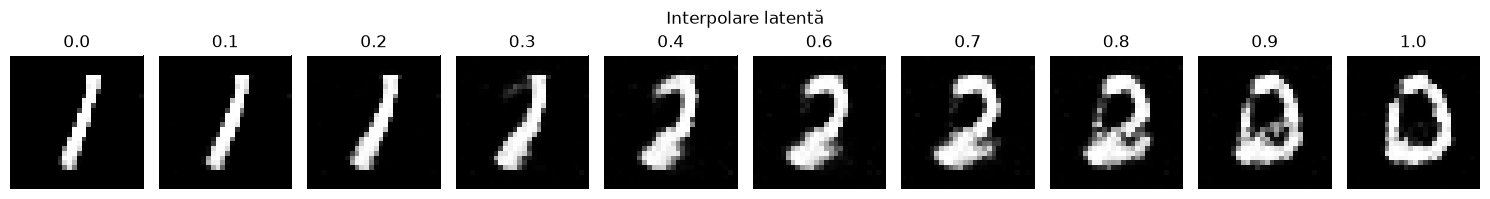

In [31]:
z1 = tf.random.normal([1, LATENT_DIM])
z2 = tf.random.normal([1, LATENT_DIM])
alphas = tf.linspace(0.0, 1.0, 10)
latent_vectors = tf.concat([(1 - a) * z1 + a * z2 for a in alphas], axis=0)
interpolated = tf.clip_by_value((generator(latent_vectors, training=False) + 1) / 2, 0, 1)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(interpolated[i, :, :, 0], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{alphas[i]:.1f}')
    ax.axis('off')
plt.suptitle('Interpolare latentă')
plt.tight_layout()
plt.show()

## 13. Salvarea modelelor
Formatul `.keras` păstrează arhitectura și ponderile. Pentru generare ulterioară este suficient generatorul.

In [32]:
generator_path = MODEL_DIR / 'generator_mnist.keras'
discriminator_path = MODEL_DIR / 'discriminator_mnist.keras'
generator.save(generator_path)
discriminator.save(discriminator_path)
print('Generator salvat:', generator_path)
print('Discriminator salvat:', discriminator_path)

loaded_generator = keras.models.load_model(generator_path)
test_output = loaded_generator(tf.random.normal([1, LATENT_DIM]), training=False)
assert test_output.shape == (1, 28, 28, 1)
print('Verificarea reîncărcării a reușit.')

Generator salvat: gan_mnist_outputs/models/generator_mnist.keras
Discriminator salvat: gan_mnist_outputs/models/discriminator_mnist.keras
Verificarea reîncărcării a reușit.


## Concluzie
Generatorul învață progresiv distribuția vizuală a cifrelor MNIST prin feedbackul discriminatorului. Calitatea unui GAN se apreciază atât prin dinamica antrenării, cât mai ales prin realismul și diversitatea exemplelor produse.